In [ ]:
import torch
import numpy as np

if torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

print(device)
tns = torch.randn((2,3))
tns = tns.to(device)
print(tns)

tns1 = torch.randn(7,7,3)
tns2 = torch.randn(147,1)
tns1 = tns1.view(-1,1) #redimensionar o tensor(-1 achata no máximo possivel)
somtns = tns1+tns2
#print(somtns)

#jogar para a gpu
tns1 = tns1.to(device)
tns2 = tns2.to(device)
somtns = tns1+tns2
#print(somtns)

cuda
tensor([[-1.1513, -1.4813, -0.9784],
        [ 1.8411, -0.1931, -0.5746]], device='cuda:0')


*tipos de variaveis que são jogadas na gpu

In [ ]:
a = -1
b = 4
c = 0.4

x = np.linspace(-2,4,50)#50 valores entre -2 e 4

Teste codigo python do projeto


GERANDO DADOS

DISTURBENCE

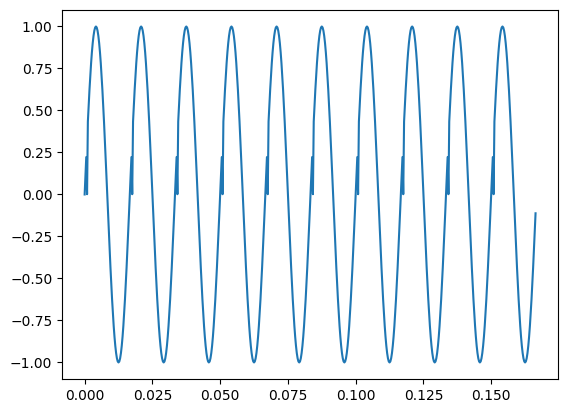

In [ ]:
# These functions implement the power-quality disturbance models proposed by
# Lee and Shen 2011.

# author: raoni at ufmt dot br

import math
from math import sin
from math import pi
import matplotlib.pyplot as plt
from numpy import arange
from numpy import multiply as mult
import numpy as np
import array as arr
import random
from enum import Enum


# global parameters
freq = 60.0  # fundamental frequency
#cycles = 10.0 # number of cycles
#sf = 6.4 * 1000 # sampling frequency
#sf = 3.2 * 1000 # sampling frequency

class PowerDisturbance(Enum):
    NORMAL = 0
    SAG = 1
    SWELL = 2
    INTERRUPTION = 3
    FLICKER = 4
    OSCILLATORY_TRANSIENT = 5
    HARMONIC = 6
    SAG_HARMONIC = 7
    SWELL_HARMONIC = 8
    NOTCH = 9
    SPIKE = 10
    INTERRUPTION_HARMONIC = 11
    FLICKER_HARMONIC = 12
    FLICKER_SAG = 13
    FLICKER_SWELL = 14
    IMPULSIVE_TRANSIENT = 15



NORMAL = 0
SAG = 1
SWELL = 2
INTERRUPTION = 3
FLICKER = 4
OSCILLATORY_TRANSIENT = 5
HARMONIC = 6
SAG_HARMONIC = 7
SWELL_HARMONIC = 8
NOTCH = 9 # normal
SPIKE = 10 # normal
INTERRUPTION_HARMONIC = 11 # normal
FLICKER_HARMONIC = 12
FLICKER_SAG = 13
FLICKER_SWELL = 14
IMPULSIVE_TRANSIENT = 15 # normal

def noise(signal, target_snr_db):

    x_watts = signal ** 2
    #target_snr_db = 20
    # Calculate signal power and convert to dB
    sig_avg_watts = np.mean(x_watts)
    sig_avg_db = 10 * np.log10(sig_avg_watts)
    # Calculate noise according to [2] then convert to watts
    noise_avg_db = sig_avg_db - target_snr_db
    noise_avg_watts = 10 ** (noise_avg_db / 10)
    # Generate an sample of white noise
    mean_noise = 0
    noise_volts = np.random.normal(mean_noise, np.sqrt(noise_avg_watts), len(x_watts))
    # Noise up the original signal
    #y_volts = x_volts + noise_volts

    return signal + noise_volts


# funcao degrau
def u(x):
    #return 1 * (x > 0)
    return np.heaviside(x, 0)

def time_sampling(f, cycles, sf):
    sr = 1/sf # periodo de amostragem
    MAX = cycles/f
    return arange(0, MAX, sr);

def normal(f, cycles, sf):
    t = time_sampling(f, cycles, sf)
    return (t, np.sin(2 * pi * f * t)) # signal

def sag(f, cycles, sf, alpha, t1, t2):

    t = time_sampling(f, cycles, sf)

    return (t, (1 - alpha*np.subtract(u(t-t1), u(t-t2)))* np.sin(2 * pi * f * t))

def swell(f, cycles, sf, alpha, t1, t2):

    t = time_sampling(f, cycles, sf)

    return (t, (1 + alpha*np.subtract(u(t-t1), u(t-t2)))* np.sin(2 * pi * f * t))

# Interruption
# Parameters variation:
# 0.9 < alpha <= 1
def interruption(f, cycles, sf, alpha, t1, t2):
    return sag(f, cycles, sf, alpha, t1, t2)

def flicker(f, cycles, sf, alpha, beta):
    t = time_sampling(f, cycles, sf)
    return (t, (1 + alpha * np.sin( 2 * pi * beta * t) * np.sin(2 * pi * f * t)))

def oscillatory_transient(f, cycles, sf, alpha, tau, fn, t1, t2):

    t = time_sampling(f, cycles, sf)


    c = alpha*np.exp(-((t-t1)/tau));
    d = np.subtract(u(t-t1), u(t-t2));
    e = np.sin(2*pi*fn*t);
    b = mult(mult(c,d), e);

    return (t, np.add(np.sin(f * 2 * pi * t), b)) # noise + signal

def harmonic(f, cycles, sf, alpha):

    t = time_sampling(f, cycles, sf)
    k = 1

    a1 = math.sqrt(1 - alpha[0]**2 - alpha[1]**2 - alpha[2]**2);
    s = a1 * np.sin(2 * pi * f * t)

    for a in alpha:
        s =  s + a * np.sin(f * 2 * pi * t * (2*k+1))
        k = k + 1

    return (t, s)

#def sag_harmonic(f, cycles, sf, alpha_s, t1, ft, alpha):
#    (t, s) = sag(f, cycles, sf, alpha_s, t1, ft)
#    (t, h) = harmonic(f, cycles, sf, alpha)
#    return (t, s * h)

def sag_harmonic(f, cycles, sf, alpha_s, t1, t2, alpha):

    # sag
    t = time_sampling(f, cycles, sf)

    s = (1 - alpha_s*np.subtract(u(t-t1), u(t-t2)))

    (t, h) = harmonic(f, cycles, sf, alpha)
    return (t, s * h)

#def swell_harmonic(f, cycles, sf, alpha_s, t1, ft, alpha):

#    (t, s) = swell(f, cycles, sf, alpha_s, t1, ft)
#    (t, h) = harmonic(f, cycles, sf, alpha)
#    return (t, s * h)

def swell_harmonic(f, cycles, sf, alpha_s, t1, t2, alpha):

    # swell
    t = time_sampling(f, cycles, sf)

    s = (1 + alpha_s*np.subtract(u(t-t1), u(t-t2)))

    (t, h) = harmonic(f, cycles, sf, alpha)
    return (t, s * h)

def notch(f, cycles, sf, k, t1, t2):

    t = time_sampling(f, cycles, sf)

    normal = np.sin(2 * pi * f * t)

    notch = np.zeros(len(t))
    for n in range(10):
        notch =  notch +  k * (u(t-(t1 + (1/freq)*n)) - u(t-(t2 + (1/freq)*n)))

    return (t, normal + np.multiply(notch, -np.sign(normal)))

def spike(f, cycles, sf, k, t1, t2):

    t = time_sampling(f, cycles, sf)

    normal = np.sin(2 * pi * f * t)

    spike = np.zeros(len(t))
    for n in range(10):
        spike =  spike +  k * (u(t-(t1 + (1/freq)*n)) - u(t-(t2 + (1/freq)*n)))

    return (t, normal + np.multiply(spike, +np.sign(normal)))

def interruption_harmonic(f, cycles, sf, alpha_i, t1, t2, alpha):

    # interruption
    t = time_sampling(f, cycles, sf)

    i = (1 - alpha_i*np.subtract(u(t-t1), u(t-t2)))

    (t, h) = harmonic(f, cycles, sf, alpha)
    return (t, i * h)

def flicker_harmonic(f, cycles, sf, alpha_f, beta_f, alpha):

    # flicker
    t = time_sampling(f, cycles, sf)
    fl = (1 + alpha_f * np.sin( 2 * pi * beta_f * t))

    (t, h) = harmonic(f, cycles, sf, alpha)
    return (t, fl*h)

def flicker_sag(f, cycles, sf, alpha, t1, t2, alpha_f, beta_f):

    # sag
    t = time_sampling(f, cycles, sf)

    s = (1 - alpha*np.subtract(u(t-t1), u(t-t2)))

    (t, fl) = flicker(f, cycles, sf, alpha_f, beta_f)

    return (t, s*fl)

def flicker_swell(f, cycles, sf, alpha, t1, t2, alpha_f, beta_f):

    # sag
    t = time_sampling(f, cycles, sf)

    s = (1 + alpha*np.subtract(u(t-t1), u(t-t2)))

    (t, fl) = flicker(f, cycles, sf, alpha_f, beta_f)

    return (t, s*fl)

def impulsive_transient(f, cycles, sf, alpha, t1, t2):
    return sag(f, cycles, sf, alpha, t1, t2)

class RandomParams:

    def __init__(self, type):

        # Global parameters
        self.f = 60.0  # frequency of fundamental
        self.cycles = 10.0 # number of cycles
        self.sf = 3.36 * 1000 # sampling frequency

        self.size = random.uniform(1,9)
        self.t1 = random.uniform(0, (10-self.size)/f)
        self.t2 = self.t1 + self.size/self.f


        if type == SWELL:
            self.alpha = random.uniform(0.1, 0.8)
            self.ft = random.uniform(1, 9)

        if type == SAG:
            self.alpha = random.uniform(0.1, 0.9)
            self.ft = random.uniform(1, 9)

        if type == INTERRUPTION:
            self.alpha = random.uniform(0.9, 1)
            self.ft = random.uniform(1, 9)

        if type == FLICKER:
            self.alpha = random.uniform(0.1, 0.2)
            self.beta = random.uniform(5, 20)

        if type == OSCILLATORY_TRANSIENT:
            self.alpha = random.uniform(0.1, 0.8)
            self.fn = random.uniform(300, 900)
            self.tau = random.uniform(8.0/1000, 40.0/1000)

            self.size = random.uniform(0.5,3)
            self.t1 = random.uniform(0, (10-self.size)/f)
            self.t2 = self.t1 + self.size/self.f



        if type == HARMONIC:
            self.alpha = []
            self.alpha.append(random.uniform(0.05, 0.15))
            self.alpha.append(random.uniform(0.05, 0.15))
            self.alpha.append(random.uniform(0.05, 0.15))

        if type == SAG_HARMONIC:
            self.alpha_s = random.uniform(0.1, 0.9)
            self.ft = random.uniform(1, 9)
            self.alpha = []
            self.alpha.append(random.uniform(0.05, 0.15))
            self.alpha.append(random.uniform(0.05, 0.15))
            self.alpha.append(random.uniform(0.05, 0.15))

        if type == SWELL_HARMONIC:
            self.alpha_s = random.uniform(0.1, 0.8)
            self.ft = random.uniform(1, 9)
            self.alpha = []
            self.alpha.append(random.uniform(0.05, 0.15))
            self.alpha.append(random.uniform(0.05, 0.15))
            self.alpha.append(random.uniform(0.05, 0.15))

        if type == NOTCH:
            self.k = random.uniform(0.1, 0.4)

            self.size = random.uniform(0.01,0.05)
            self.t1 = random.uniform(0, 0.5/f)
            self.t2 = self.t1 + self.size/self.f


        if type == SPIKE:
            self.k = random.uniform(0.1, 0.4)

            self.size = random.uniform(0.01,0.05)
            self.t1 = random.uniform(0, 0.5/f)
            self.t2 = self.t1 + self.size/self.f



        if type == INTERRUPTION_HARMONIC:
            self.alpha_i = random.uniform(0.9, 1)

            self.alpha = []
            self.alpha.append(random.uniform(0.05, 0.15))
            self.alpha.append(random.uniform(0.05, 0.15))
            self.alpha.append(random.uniform(0.05, 0.15))

        if type == FLICKER_HARMONIC:
            self.alpha_f = random.uniform(0.1, 0.2)
            self.beta_f = random.uniform(5, 20)
            self.alpha = []
            self.alpha.append(random.uniform(0.05, 0.15))
            self.alpha.append(random.uniform(0.05, 0.15))
            self.alpha.append(random.uniform(0.05, 0.15))

        if type == FLICKER_SAG:
            self.alpha_f = random.uniform(0.1, 0.2)
            self.beta_f = random.uniform(5, 20)
            self.alpha = random.uniform(0.1, 0.9)

        if type == FLICKER_SWELL:
            self.alpha_f = random.uniform(0.1, 0.2)
            self.beta_f = random.uniform(5, 20)
            self.alpha = random.uniform(0.1, 0.8)


        if type == IMPULSIVE_TRANSIENT:
            self.alpha = random.uniform(0, 0.414)

            self.size = random.uniform(0.05,0.1)
            self.t1 = random.uniform(0, (10-self.size)/f)
            self.t2 = self.t1 + self.size/self.f



f = 60.0  # frequency of fundamental
cycles = 10.0 # number of cycles
sf = 3.36 * 1000
ideal = normal(f = f, cycles = cycles, sf = sf)

def disturbance(type, params):

    if type == NORMAL:
        return normal(f = params.f, cycles = params.cycles, sf = params.sf)

    if type == SWELL:
        return swell(f = params.f, cycles = params.cycles, sf = params.sf, alpha = params.alpha, t1 = params.t1, t2 = params.t2)

    if type == SAG:
        return sag(f = params.f, cycles = params.cycles, sf = params.sf, alpha = params.alpha, t1 = params.t1, t2 = params.t2)

    if type == INTERRUPTION:
        return interruption(f = params.f, cycles = params.cycles, sf = params.sf, alpha = params.alpha, t1 = params.t1, t2 = params.t2)

    if type == FLICKER:
        return flicker(f = params.f, cycles = params.cycles, sf = params.sf, alpha = params.alpha,  beta = params.beta)

    if type == OSCILLATORY_TRANSIENT:
        return oscillatory_transient(f = params.f, cycles = params.cycles, sf = params.sf, alpha = params.alpha, tau = params.tau, fn = params.fn, t1 = params.t1, t2 = params.t2)

    if type == HARMONIC:
        return harmonic(f = params.f, cycles = params.cycles, sf = params.sf, alpha = params.alpha)

    if type == SAG_HARMONIC:
        return sag_harmonic(f = params.f, cycles = params.cycles, sf = params.sf, alpha_s = params.alpha_s, alpha = params.alpha, t1=params.t1, t2=params.t2)

    if type == SWELL_HARMONIC:
        return swell_harmonic(f = params.f, cycles = params.cycles, sf = params.sf, alpha_s = params.alpha_s, alpha = params.alpha, t1=params.t1, t2=params.t2)

    if type == NOTCH:
        #print(params.k)
        #print(params.ft)
        notch_sig = notch(f = params.f, cycles = params.cycles, sf = params.sf, k = params.k, t1 = params.t1, t2 = params.t2)
        #while np.array_equal(notch_sig, ideal):
        #    print params.k,  params.ft, params.t2
        #    params = RandomParams(NOTCH)
        #    notch_sig = notch(f = params.f, cycles = params.cycles, sf = params.sf, k = params.k, t2 = params.t2, ft = params.ft)
            #print "ERRO"
        return notch_sig

    if type == SPIKE:
        return spike(f = params.f, cycles = params.cycles, sf = params.sf, k = params.k, t1 = params.t1, t2 = params.t2)

    if type == INTERRUPTION_HARMONIC:
        return interruption_harmonic(f = params.f, cycles = params.cycles, sf = params.sf, alpha_i = params.alpha_i, alpha = params.alpha, t1=params.t1, t2=params.t2)

    if type == FLICKER_HARMONIC:
        return flicker_harmonic(f = params.f, cycles = params.cycles, sf = params.sf, alpha_f = params.alpha_f, beta_f = params.beta_f, alpha = params.alpha)

    if type == FLICKER_SAG:
        return flicker_sag(f = params.f, cycles = params.cycles, sf = params.sf, alpha = params.alpha, t1 = params.t1, t2 = params.t2, beta_f = params.beta_f, alpha_f = params.alpha_f)

    if type == FLICKER_SWELL:
        return flicker_swell(f = params.f, cycles = params.cycles, sf = params.sf, alpha = params.alpha, t1 = params.t1, t2 = params.t2, beta_f = params.beta_f, alpha_f = params.alpha_f)

    if type == IMPULSIVE_TRANSIENT:
        return impulsive_transient(f = params.f, cycles = params.cycles, sf = params.sf, alpha = params.alpha, t1 = params.t1, t2 = params.t2)


def random_disturbance(type):
    params = RandomParams(type)
    signal = disturbance(type, params)

    if type != NORMAL:
        while np.array_equal(signal, ideal):
            params = RandomParams(type)
            signal = disturbance(type, params)

    return signal

def random_disturbance_noise(type, snr_db):
    params = RandomParams(type)
    (x, signal) = disturbance(type, params)
    noise_signal =  noise(signal, snr_db)
    return (x, noise_signal)

(x, y) = interruption(f, cycles, sf, 0.99, 0.14, 3)
(x, y) = flicker(f, cycles, sf, 0.1, 5)
(x, y) = oscillatory_transient(f, cycles, sf, alpha = 0.8, tau = 20.0/1000, fn = 500, t1 = 0.041, t2 = 1.8)
(x, y) = harmonic(f = f, cycles = cycles, sf = sf, alpha = [0.15, 0.15, 0.15])
(x, y) = sag_harmonic(f, cycles, sf, 0.9, 0.041, 1.5, [0.15, 0.15, 0])
(x, y) = swell_harmonic(f, cycles, sf, 0.9, 0.041, 1.5, [0.15, 0.15, 0])
(x, y) = notch(f, cycles, sf, 0.1, 0.041, 0.05)
(x, y) = spike(f, cycles, sf, 0.4, 0.041, 0.1)
#print x.shape
#print y.shape
#plt.plot(x, y)
#plt.show()


#params = RandomParams(9)
#print(params.t1)
#print(params.t2)
#print(params.k)
#print('---')
#(x,y) = disturbance(9, params)
#plt.plot(x, y)
#plt.show()

params = RandomParams(9)
#print(params.t1)
#print(params.t2)
#print(params.k)
(x,y) = disturbance(9, params)
plt.plot(x, y)
#plt.show()
plt.savefig('notch.png')

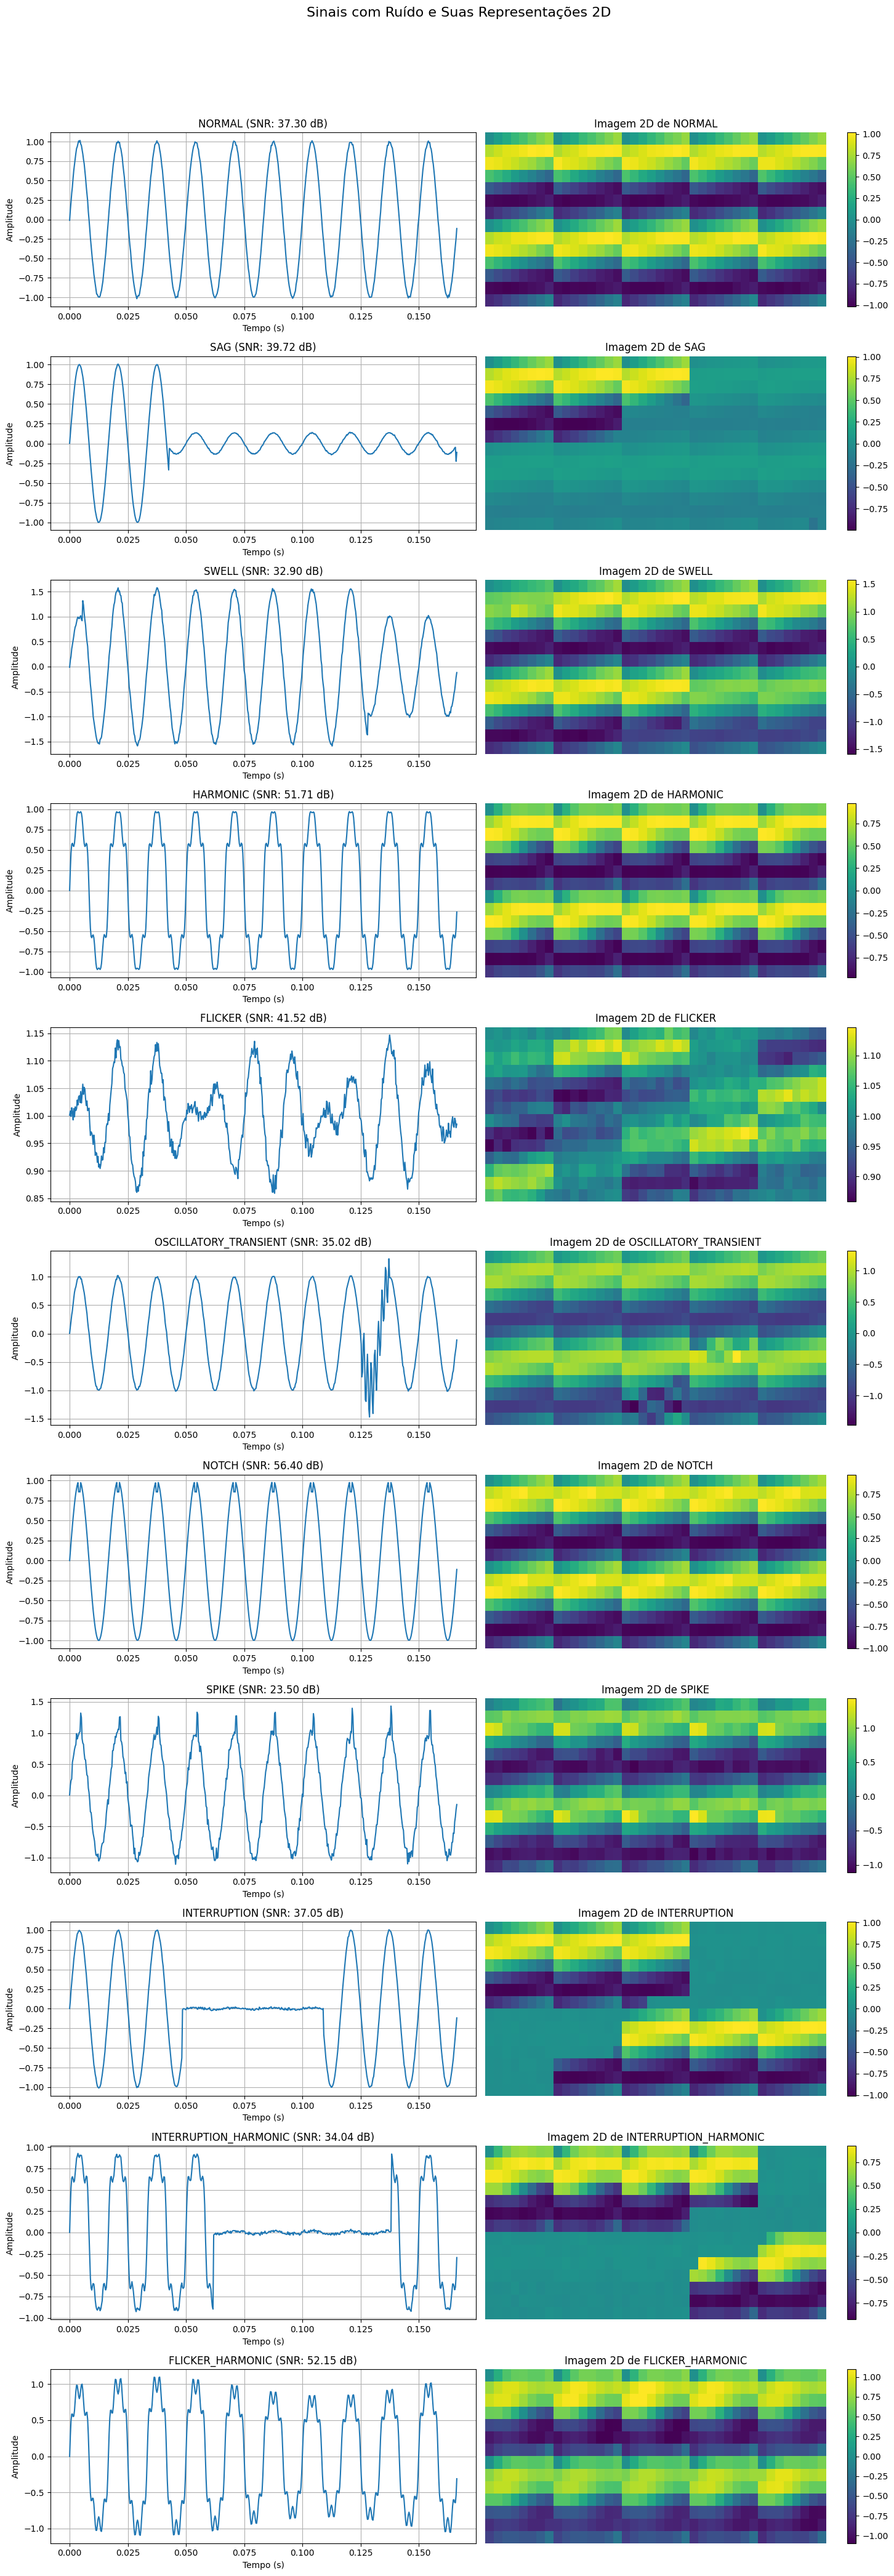

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Define a list of disturbance types to visualize
disturbance_types_to_plot = [
    PowerDisturbance.NORMAL,
    PowerDisturbance.SAG,
    PowerDisturbance.SWELL,
    PowerDisturbance.HARMONIC,
    PowerDisturbance.FLICKER,
    PowerDisturbance.OSCILLATORY_TRANSIENT,
    PowerDisturbance.NOTCH,
    PowerDisturbance.SPIKE,
    PowerDisturbance.INTERRUPTION,
    PowerDisturbance.INTERRUPTION_HARMONIC,
    PowerDisturbance.FLICKER_HARMONIC,
]

# Set up the plot for multiple subplots
num_types = len(disturbance_types_to_plot)
fig, axes = plt.subplots(num_types, 2, figsize=(15, 4 * num_types))
fig.suptitle('Sinais com Ruído e Suas Representações 2D', fontsize=16)

for i, dist_type in enumerate(disturbance_types_to_plot):
    # Generate a signal with random noise (SNR between 20 and 60 dB)
    snr_db = np.random.uniform(20, 60)
    (time_points, noisy_signal) = random_disturbance_noise(dist_type.value, snr_db)

    # Convert the noisy signal to its 2D representation
    img_2d = to2D(noisy_signal)

    # Plot the noisy signal
    axes[i, 0].plot(time_points, noisy_signal)
    axes[i, 0].set_title(f'{dist_type.name} (SNR: {snr_db:.2f} dB)')
    axes[i, 0].set_xlabel('Tempo (s)')
    axes[i, 0].set_ylabel('Amplitude')
    axes[i, 0].grid(True)

    # Plot the 2D image
    im = axes[i, 1].imshow(img_2d, aspect='auto', cmap='viridis')
    axes[i, 1].set_title(f'Imagem 2D de {dist_type.name}')
    axes[i, 1].axis('off') # Hide axes for image plot
    fig.colorbar(im, ax=axes[i, 1])

plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust layout to prevent suptitle overlap
plt.show()

TO2D


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.misc
from PIL import Image

#from disturbances import *

def to2D(x2):
    result = np.zeros(shape = (14, 40))

    F = 56

    for k in range(0,5):
        arr = x2[F*k:(k+1)*F]
        m = arr.reshape(7,8)
        result[0:7,k*8:(k+1)*8] = m

    for k in range(5,10):
        arr = x2[F*k:(k+1)*F]
        m = arr.reshape(7,8)
        z = k - 5
        result[7:14,(z)*8:(z+1)*8] = m


    return result


def to2D2(x2):
    result = np.zeros(shape = (32, 40))

    F = 128

    for k in range(0,5):
        arr = x2[F*k:(k+1)*F]
        m = arr.reshape(16,8)
        result[0:16,k*8:(k+1)*8] = m

    for k in range(5,10):
        arr = x2[F*k:(k+1)*F]
        m = arr.reshape(16,8)
        z = k - 5
        result[16:32,(z)*8:(z+1)*8] = m


    return result


def periodicSignal(k):
    (x1, x2) = random_disturbance(k)
    r = to2D(x2)

    #plt.imshow(r)
    #plt.show()

    s = r.shape
    rgbArray = np.zeros(shape = (s[0],s[1],3), dtype = np.float32)
    rgbArray[..., 0] = r
    rgbArray[..., 1] = r
    rgbArray[..., 2] = r

    return rgbArray

def randomPeriodicSignal(k):
    (x1, x2) = random_disturbance(k)
    return (to2D(x2), x2)

def randomPeriodicSignalNoise(k, snr_db):
    (x1, x2) = random_disturbance_noise(k, snr_db)
    return (to2D(x2), x2)#to2D(x2)

#plt.plot(x1,x2)
#plt.show()

#F = len(x2) / 10

#plt.plot(x1[:F],x2[:F])
#plt.show()

#r = to2D(x2)

#plt.imshow(r)
#plt.show()
#print r.shape


# zeros = np.zeros(shape = (16, 40))
#
#
# for k in range(0,5):
#     arr = x2[64*k:(k+1)*64]
#     m = arr.reshape(8,8)
#     zeros[0:8,k*8:(k+1)*8] = m
#
# for k in range(5,10):
#     arr = x2[64*k:(k+1)*64]
#     m = arr.reshape(8,8)
#     z = k - 5
#     zeros[8:16,(z)*8:(z+1)*8] = m


# plt.imshow(zeros)
# plt.show()



# plt.plot(x1[64*k:(k+1)*64], x2[64*k:(k+1)*64])
# plt.show()
#
# arr = x2[64*k:(k+1)*64]
# m = arr.reshape(8,8)
# plt.imshow(m)
# plt.show()

/tmp/ipykernel_3754/4202849404.py:3: DeprecationWarning: scipy.misc is deprecated and will be removed in 2.0.0
  import scipy.misc


CREATE DATABASE NOTCH

In [ ]:
import cv2
import datetime as dt
import h5py
import matplotlib.pyplot as plt
import matplotlib.pylab as plb
import numpy as np
import os
import pandas as pd
from glob import glob
import random

import itertools
from itertools import repeat, chain

#from to2d import *
#from disturbances import *

def proc_images_notch(num, name):
    """
    Saves compressed, resized images as HDF5 datsets
    Returns
        data.h5, where each dataset is an image or class label
        e.g. X23,y23 = image and corresponding class label
    """

    # Size of data
    #NUM_IMAGES = len(images)
    HEIGHT = 14
    WIDTH = 40
    CHANNELS = 1
    SHAPE = (HEIGHT, WIDTH)

    #quantidade de disturbios
    lst = [NOTCH]#range(0,16)
    NUM_IMAGES_PER_CLASS = num #48000
    labels = list(chain.from_iterable(repeat(x, NUM_IMAGES_PER_CLASS) for x in lst))
    #random.shuffle(labels)

    #name = 'data_wnoise_2.h5'
    with h5py.File(name, 'w') as hf:
            i = 1

            for k in labels:
                print(i)
                (image, signal) = randomPeriodicSignal(k)
                #image = randomPeriodicSignalNoise(k, 20.0)

                Xset = hf.create_dataset(
                    name='X'+str(i),
                    data=image,
                    shape=(HEIGHT, WIDTH),
                    maxshape=(HEIGHT, WIDTH))

                yset = hf.create_dataset(
                    name='y'+str(i),
                    shape=(1,),
                    data=k,
                    maxshape=(None,))
                '''
                Sset = hf.create_dataset(
                    name='S'+str(i),
                    data=signal,
                    shape=(1, WIDTH*HEIGHT),
                    maxshape=(1, HEIGHT*WIDTH))
                '''

                i = i + 1
    print (i-1)

#proc_images(48000, './data/wnoise.h5')
proc_images_notch(1000, './data/wnoise_notch.h5')

FileNotFoundError: [Errno 2] Unable to synchronously create file (unable to open file: name = './data/wnoise_notch.h5', errno = 2, error message = 'No such file or directory', flags = 13, o_flags = 242)

CREATE DATABASE


In [ ]:
from itertools import repeat, chain

import h5py

#from disturbances import *
#from to2d import *
import os
import random


def proc_images(num, name, snr_db):
    """
    Saves compressed, resized images as HDF5 datsets
    Returns
        data.h5, where each dataset is an image or class label
        e.g. X23,y23 = image and corresponding class label
    """

    # Size of data
    #NUM_IMAGES = len(images)
    HEIGHT = 14
    WIDTH = 40
    CHANNELS = 1
    SHAPE = (HEIGHT, WIDTH)

    #quantidade de disturbios
    lst = range(0,16)
    NUM_IMAGES_PER_CLASS = num #48000
    labels = list(chain.from_iterable(repeat(x, NUM_IMAGES_PER_CLASS) for x in lst))
    random.shuffle(labels)

    #snr_values = [float("inf") 20 30 40 50]
    #name = 'data_wnoise_2.h5'
    with h5py.File(name, 'w') as hf:
            i = 1
            #g1 = hf.create_group('X')
            for k in labels:
                print(i)



                if snr_db == float("inf"):
                    (image, signal) = randomPeriodicSignal(k)
                else:
                    (image, signal) = randomPeriodicSignalNoise(k, snr_db)


                Xset = hf.create_dataset(
                    name='X'+str(i),
                    data=image,
                    shape=(HEIGHT, WIDTH),
                    maxshape=(HEIGHT, WIDTH))

                yset = hf.create_dataset(
                    name='y'+str(i),
                    shape=(1,),
                    data=k,
                    maxshape=(None,))


                Sset = hf.create_dataset(
                    name='S'+str(i),
                    data=signal,
                    shape=(1, WIDTH*HEIGHT),
                    maxshape=(1, HEIGHT*WIDTH))


                i = i + 1
    print(i-1)


def proc_images_random(num, name):
    """
    Saves compressed, resized images as HDF5 datsets
    Returns
        data.h5, where each dataset is an image or class label
        e.g. X23,y23 = image and corresponding class label
    """

    # Size of data
    #NUM_IMAGES = len(images)
    HEIGHT = 14
    WIDTH = 40
    CHANNELS = 1
    SHAPE = (HEIGHT, WIDTH)

    #quantidade de disturbios
    lst = range(0,16)
    NUM_IMAGES_PER_CLASS = num #48000
    labels = list(chain.from_iterable(repeat(x, NUM_IMAGES_PER_CLASS) for x in lst))
    random.shuffle(labels)

    #snr_values = [float("inf") 20 30 40 50]
    #name = 'data_wnoise_2.h5'
    # Create the directory if it doesn't exist
    directory = os.path.dirname(name)
    if not os.path.exists(directory):
        os.makedirs(directory)

    # Delete the file if it exists
    if os.path.exists(name):
        os.remove(name)

    with h5py.File(name, 'w') as hf:
            i = 1
            #g1 = hf.create_group('X')
            for k in labels:
                print(i)

                snr_db = random.uniform(20, 60)

                #if snr_db == float("inf"):
                #    (image, signal) = randomPeriodicSignal(k)
                #else:
                (image, signal) = randomPeriodicSignalNoise(k, snr_db)


                Xset = hf.create_dataset(
                    name='X'+str(i),
                    data=image,
                    shape=(HEIGHT, WIDTH),
                    maxshape=(HEIGHT, WIDTH))

                yset = hf.create_dataset(
                    name='y'+str(i),
                    shape=(1,),
                    data=k,
                    maxshape=(None,))


                Sset = hf.create_dataset(
                    name='S'+str(i),
                    data=signal,
                    shape=(1, WIDTH*HEIGHT),
                    maxshape=(1, HEIGHT*WIDTH))


                i = i + 1
    print(i-1)


#proc_images(48000, './data/wnoise.h5')
#proc_images(1000, './data/wnoise_test.h5')
#proc_images(48000, './data/30db_train.h5')
#proc_images(1000, './data/30db_test.h5')

#proc_images(48000, './data/40db_train.h5', 40.0)
#proc_images(1000, './data/40db_test.h5', 40.0)

#proc_images(1000, './data/wn_test.h5', float("inf"))
#proc_images(48000, './data/train_sig.h5', float("inf"))
#proc_images(2000, './data/test_sig.h5', float("inf"))


proc_images_random(4800, './data_random/train_sig.h5')#48000
#proc_images(2000, './data/test_sig.h5', float("inf"))


#proc_images_random(48000, './data/pqd_1d.h5')


#proc_images_random(10, './data/test_ricardo.h5')

A saída de streaming foi truncada nas últimas 5000 linhas.
71802
71803
[... 4995 linhas de progresso omitidas ...]
76799
76800
76800


# MODELO DE IA ANTIGO(KERAS)

# MODELO PYTORCH


MODELO 4

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader, random_split
import numpy as np
import os

# --- Configurações e Parâmetros ---
# Simula a importação de funções de leitura de dados
# Em um caso real, você implementaria essas funções para carregar seus dados
def load_data(filename, T):
    print(f"Carregando dados de {filename}...")
    # Dados e rótulos aleatórios para fins de demonstração
    # O formato de entrada do Keras (channels_last) é (N, H, W, C)
    #x_train_demo = np.random.rand(T, 14, 40, 1).astype('float32')
    #y_train_demo = np.random.randint(0, 16, T).astype('int64') # Rótulos como índices de classe
    return torch.from_numpy(x_train_demo), torch.from_numpy(y_train_demo)

class H5Dataset(torch.utils.data.Dataset):
    def __init__(self, path):
        self.h5 = h5py.File(path, 'r')
        self.n = len([k for k in self.h5.keys() if k.startswith('X')])
    def __len__(self):
        return self.n
    def __getitem__(self, idx):
        X = self.h5[f'X{idx+1}'][:]     # shape (14,40)
        y = int(self.h5[f'y{idx+1}'][0])
        # normalize X aqui (ver abaixo)
        return torch.from_numpy(X).unsqueeze(0).float(), y


# Parâmetros do modelo e treinamento
PATIENCE = 10
NUM_TRAIN_IMAGES = 768000 # Reduzido para uma execução mais rápida neste exemplo
batch_size = 256
num_classes = 16
epochs = 50 # Reduzido para uma execução mais rápida neste exemplo
img_rows, img_cols = 14, 40
input_channels = 1 # Apenas 1 canal (escala de cinza)

# Arquivos e diretórios
filename = './data_random/train_sig.h5'
checkpoint_path = "./output_random_pytorch/"
checkpoint_file = os.path.join(checkpoint_path, "iris_2d_4.pth")

# Criar diretório de checkpoint se não existir
if not os.path.exists(checkpoint_path):
    os.makedirs(checkpoint_path)

# --- Definição do Modelo (Arquitetura da Rede) ---
class ConvNet(nn.Module):
    def __init__(self, num_classes=16):
        super(ConvNet, self).__init__()
        # PyTorch espera a entrada como (N, C, H, W)
        # Camadas convolucionais
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, padding=1) # padding=1 para simular 'same'
        self.conv2 = nn.Conv2d(in_channels=16, out_channels=16, kernel_size=3, padding=1)
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)

        self.conv3 = nn.Conv2d(in_channels=16, out_channels=8, kernel_size=3, padding=1)
        self.conv4 = nn.Conv2d(in_channels=8, out_channels=8, kernel_size=3, padding=1)
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)

        self.conv5 = nn.Conv2d(in_channels=8, out_channels=8, kernel_size=3, padding=1)
        self.conv6 = nn.Conv2d(in_channels=8, out_channels=8, kernel_size=3, padding=1)
        self.pool3 = nn.MaxPool2d(kernel_size=2, stride=2)

        self.conv7 = nn.Conv2d(in_channels=8, out_channels=8, kernel_size=3, padding=1)
        self.conv8 = nn.Conv2d(in_channels=8, out_channels=8, kernel_size=3, padding=1)
        # Equivalente ao GlobalMaxPooling2D: pooling adaptativo para uma saída 1x1
        self.global_pool = nn.AdaptiveMaxPool2d((1, 1))

        # Camadas totalmente conectadas (Dense)
        self.fc1 = nn.Linear(in_features=8, out_features=128)
        self.fc2 = nn.Linear(in_features=128, out_features=64)
        self.fc3 = nn.Linear(in_features=64, out_features=num_classes)

    def forward(self, x):
        # Bloco convolucional 1
        x = F.relu(self.conv1(x))
        x = F.relu(self.conv2(x))
        x = self.pool1(x)

        # Bloco convolucional 2
        x = F.relu(self.conv3(x))
        x = F.relu(self.conv4(x))
        x = self.pool2(x)

        # Bloco convolucional 3
        x = F.relu(self.conv5(x))
        x = F.relu(self.conv6(x))
        x = self.pool3(x)

        # Bloco convolucional 4 com Global Pooling
        x = F.relu(self.conv7(x))
        x = F.relu(self.conv8(x))
        x = self.global_pool(x)

        # Achatamento do tensor antes de passar para as camadas densas
        # O formato de x agora é (batch_size, 8, 1, 1)
        x = torch.flatten(x, 1) # Achatamento a partir da dimensão 1

        # Camadas densas
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        # A camada de saída não precisa de softmax aqui, pois nn.CrossEntropyLoss a aplica internamente
        x = self.fc3(x)
        return x

# --- Preparação dos Dados ---
# Carregar os dados
x_data, y_data = load_data(filename, T=NUM_TRAIN_IMAGES)

# Mudar a ordem das dimensões para o formato do PyTorch: (N, H, W, C) -> (N, C, H, W)
x_data = x_data.permute(0, 3, 1, 2)

# Criar o dataset
dataset = TensorDataset(x_data, y_data)

# Dividir em conjuntos de treinamento e validação (90% treino, 10% validação)
train_size = int(0.9 * len(dataset))
val_size = len(dataset) - train_size
train_dataset, val_dataset = random_split(dataset, [train_size, val_size])

# Criar DataLoaders para carregar os dados em lotes
train_loader = DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(dataset=val_dataset, batch_size=batch_size, shuffle=False)

# --- Inicialização para o Treinamento ---
# Definir o dispositivo (GPU se disponível, senão CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Usando dispositivo: {device}")

# Instanciar o modelo e movê-lo para o dispositivo
model = ConvNet(num_classes=num_classes).to(device)
print(model)

# Definir a função de perda (Loss Function) e o otimizador
# nn.CrossEntropyLoss combina Softmax e NLLLoss. Espera rótulos como índices de classe.
criterion = nn.CrossEntropyLoss()
# Adadelta é o otimizador correspondente
optimizer = optim.Adadelta(model.parameters())

# --- Loop de Treinamento e Validação ---
best_val_acc = 0.0
epochs_no_improve = 0

for epoch in range(epochs):
    # --- Fase de Treinamento ---
    model.train() # Coloca o modelo em modo de treinamento
    running_loss = 0.0
    correct_train = 0
    total_train = 0

    for i, (inputs, labels) in enumerate(train_loader):
        # Mover dados para o dispositivo
        inputs, labels = inputs.to(device), labels.to(device)

        # 1. Zerar os gradientes do otimizador
        optimizer.zero_grad()

        # 2. Forward pass: calcular a saída do modelo
        outputs = model(inputs)

        # 3. Calcular a perda
        loss = criterion(outputs, labels)

        # 4. Backward pass: calcular os gradientes da perda
        loss.backward()

        # 5. Atualizar os pesos do modelo
        optimizer.step()

        # Calcular estatísticas
        running_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()

    train_loss = running_loss / len(train_loader)
    train_acc = 100 * correct_train / total_train

    # --- Fase de Validação ---
    model.eval() # Coloca o modelo em modo de avaliação
    running_val_loss = 0.0
    correct_val = 0
    total_val = 0

    with torch.no_grad(): # Desativa o cálculo de gradientes para a validação
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            running_val_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            total_val += labels.size(0)
            correct_val += (predicted == labels).sum().item()

    val_loss = running_val_loss / len(val_loader)
    val_acc = 100 * correct_val / total_val

    print(f'Epoch [{epoch+1}/{epochs}] | '
          f'Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}% | '
          f'Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2f}%')

    # --- Lógica de ModelCheckpoint e EarlyStopping ---
    # ModelCheckpoint: Salvar o melhor modelo
    if val_acc > best_val_acc:
        print(f'Acurácia de validação melhorou ({best_val_acc:.2f}% -> {val_acc:.2f}%). Salvando modelo...')
        torch.save(model.state_dict(), checkpoint_file)
        best_val_acc = val_acc
        epochs_no_improve = 0 # Resetar contador de paciência
    else:
        epochs_no_improve += 1

    # EarlyStopping: Parar o treinamento se não houver melhora
    if epochs_no_improve >= PATIENCE:
        print(f'Sem melhora na validação por {PATIENCE} épocas. Parando o treinamento.')
        break

print('Treinamento finalizado.')

Carregando dados de ./data_random/train_sig.h5...


NameError: name 'x_train_demo' is not defined

# codigos funcionando

In [ ]:
import os
import h5py
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split
import numpy as np

# --- 1. Dataset para ler HDF5 em vez de dados aleatórios ---
class H5Dataset(Dataset):
    def __init__(self, path):
        self.h5 = h5py.File(path, 'r')
        # conta quantos conjuntos X existem
        self.n = len([k for k in self.h5.keys() if k.startswith('X')])

    def __len__(self):
        return self.n

    def __getitem__(self, idx):
        # carrega imagem e label
        X = self.h5[f'X{idx+1}'][:]                # shape (14, 40)
        y = int(self.h5[f'y{idx+1}'][0])           # label escalar
        # --- 2. Normalização: média 0, desvio 1 ---
        X = (X - X.mean()) / (X.std() + 1e-6)
        # adiciona canal
        X = np.expand_dims(X, axis=0)              # (1,14,40)
        return torch.from_numpy(X).float(), y

# --- 3. Arquitetura com BatchNorm e Dropout ---
class ConvNet(nn.Module):
    def __init__(self, num_classes=16):
        super().__init__()
        # conv block 1
        self.conv1 = nn.Conv2d(1, 16, 3, padding=1)
        self.bn1   = nn.BatchNorm2d(16)
        self.conv2 = nn.Conv2d(16,16,3, padding=1)
        self.bn2   = nn.BatchNorm2d(16)
        self.pool1 = nn.MaxPool2d(2,2)
        # conv block 2
        self.conv3 = nn.Conv2d(16,8,3, padding=1)
        self.bn3   = nn.BatchNorm2d(8)
        self.conv4 = nn.Conv2d(8,8,3, padding=1)
        self.bn4   = nn.BatchNorm2d(8)
        self.pool2 = nn.MaxPool2d(2,2)
        # conv block 3
        self.conv5 = nn.Conv2d(8,8,3, padding=1)
        self.bn5   = nn.BatchNorm2d(8)
        self.conv6 = nn.Conv2d(8,8,3, padding=1)
        self.bn6   = nn.BatchNorm2d(8)
        self.pool3 = nn.MaxPool2d(2,2)
        # conv block 4 + global pool
        self.conv7 = nn.Conv2d(8,8,3, padding=1)
        self.bn7   = nn.BatchNorm2d(8)
        self.conv8 = nn.Conv2d(8,8,3, padding=1)
        self.bn8   = nn.BatchNorm2d(8)
        self.global_pool = nn.AdaptiveMaxPool2d((1,1))
        # fc layers with dropout
        self.fc1 = nn.Linear(8,128)
        self.drop = nn.Dropout(0.3)
        self.fc2 = nn.Linear(128,64)
        self.fc3 = nn.Linear(64, num_classes)

    def forward(self, x):
        # block1
        x = F.relu(self.bn1(self.conv1(x)))
        x = F.relu(self.bn2(self.conv2(x)))
        x = self.pool1(x)
        # block2
        x = F.relu(self.bn3(self.conv3(x)))
        x = F.relu(self.bn4(self.conv4(x)))
        x = self.pool2(x)
        # block3
        x = F.relu(self.bn5(self.conv5(x)))
        x = F.relu(self.bn6(self.conv6(x)))
        x = self.pool3(x)
        # block4 + global
        x = F.relu(self.bn7(self.conv7(x)))
        x = F.relu(self.bn8(self.conv8(x)))
        x = self.global_pool(x)
        x = torch.flatten(x,1)
        # fc
        x = F.relu(self.fc1(x))
        x = self.drop(x)
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x

# --- 4. Configurações de treino atualizadas ---
batch_size = 64                     # reduzido para caber na GPU/CPU
num_classes = 16
epochs = 50

# caminhos
h5file = './data_random/train_sig.h5'
checkpoint_path = './output_random_pytorch/'
checkpoint_file = os.path.join(checkpoint_path, 'best_model.pth')
if not os.path.exists(checkpoint_path): os.makedirs(checkpoint_path)

# --- Preparar DataLoader real ---
dataset = H5Dataset(h5file)
train_size = int(0.9 * len(dataset))
val_size   = len(dataset) - train_size
train_ds, val_ds = random_split(dataset, [train_size, val_size])
train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
val_loader   = DataLoader(val_ds,   batch_size=batch_size, shuffle=False)

# dispositivo
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# instanciar modelo
model = ConvNet(num_classes).to(device)
print(model)

# loss e optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)        # trocado para Adam
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=3)

# --- Treino com EarlyStopping simplificado ---
best_val_acc = 0.0
epochs_no_improve = 0
PATIENCE = 20

for epoch in range(1, epochs+1):
    # train
    model.train()
    total, correct, running_loss = 0,0,0.0
    for X, y in train_loader:
        X,y = X.to(device), y.to(device)
        optimizer.zero_grad()
        out = model(X)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
        preds = out.argmax(dim=1)
        correct += (preds == y).sum().item()
        total += y.size(0)
    train_loss = running_loss / len(train_loader)
    train_acc  = 100 * correct / total

    # validação
    model.eval()
    v_loss, v_corr, v_tot = 0.0,0,0
    with torch.no_grad():
        for X,y in val_loader:
            X,y = X.to(device), y.to(device)
            out = model(X)
            L = criterion(out,y)
            v_loss += L.item()
            preds = out.argmax(dim=1)
            v_corr += (preds == y).sum().item()
            v_tot += y.size(0)
    val_loss = v_loss / len(val_loader)
    val_acc  = 100 * v_corr / v_tot

    # ajustar lr
    scheduler.step(val_loss)

    print(f"Epoch {epoch}/{epochs} | "
          f"Train Loss: {train_loss:.4f}, Acc: {train_acc:.2f}% | "
          f"Val Loss: {val_loss:.4f}, Acc: {val_acc:.2f}%")

    # salvar melhor modelo
    if val_acc > best_val_acc:
        print(f"Validation acc improved {best_val_acc:.2f}% -> {val_acc:.2f}%. Saving model.")
        torch.save(model.state_dict(), checkpoint_file)
        best_val_acc = val_acc
        epochs_no_improve = 0
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= PATIENCE:
            print(f"No improvement for {PATIENCE} epochs. Early stopping.")
            break

print("Training complete.")


Using device: cuda
ConvNet(
  (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv2): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv3): Conv2d(16, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn3): BatchNorm2d(8, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv4): Conv2d(8, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn4): BatchNorm2d(8, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv5): Conv2d(8, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn5): BatchNorm2d(8, eps=1e-05, momentum=0.1, affine=True, track

## CNN 1D


In [ ]:

import os
import h5py
import numpy as np
import random
from itertools import repeat, chain
#from disturbances import * # Assuming disturbances module is available in the environment

def create_1d_database(num_per_class, name):
    """
    Gera e salva os sinais 1D e seus rótulos em um arquivo HDF5.
    O formato é adequado para uma CNN 1D.
    """

    # --- MUDANÇA 1: Definir o comprimento do sinal ---
    # O comprimento do sinal é determinado pelos parâmetros de amostragem.
    # (10 ciclos / 60 Hz) * 3360 amostras/seg = 560 pontos.
    # Este valor era o total de pixels da imagem 2D (14x40).
    SIGNAL_LENGTH = 560

    # Garante que o diretório de saída exista
    directory = os.path.dirname(name)
    if directory and not os.path.exists(directory):
        os.makedirs(directory)

    # Deleta o arquivo se já existir para evitar erros
    if os.path.exists(name):
        os.remove(name)

    # Cria a lista de rótulos e a embaralha
    disturbance_types = range(0, 16)
    labels = list(chain.from_iterable(repeat(x, num_per_class) for x in disturbance_types))
    random.shuffle(labels)

    total_signals = len(labels)
    print(f"Gerando {total_signals} sinais para o arquivo {name}...")

    with h5py.File(name, 'w') as hf:
        # --- MUDANÇA 2: Pré-alocar os datasets para eficiência ---
        # Em vez de criar um dataset por imagem, criamos um grande para todos os dados.
        # Isso é muito mais rápido e eficiente.
        X_dset = hf.create_dataset('X',
                                   shape=(total_signals, SIGNAL_LENGTH, 1),
                                   dtype='float32')
        y_dset = hf.create_dataset('y',
                                   shape=(total_signals,),
                                   dtype='int64')

        for i, k in enumerate(labels):
            if (i + 1) % 1000 == 0:
                print(f"Processando sinal {i+1}/{total_signals}...")

            # Gera um valor aleatório de Relação Sinal-Ruído (SNR)
            snr_db = random.uniform(20, 60)

            # --- MUDANÇA 3: Chamar diretamente a função de geração de sinal 1D ---
            # Não usamos mais a conversão para 2D. Pegamos o sinal bruto.
            # Assuming random_disturbance_noise is defined and available
            # from disturbances import random_disturbance_noise
            # (time, signal_1d) = random_disturbance_noise(k, snr_db)

            # Placeholder for signal_1d generation if disturbances is not available
            # Replace with actual call to random_disturbance_noise when disturbances is available
            signal_1d = np.random.randn(SIGNAL_LENGTH)


            # Garante que o sinal tenha o comprimento exato, cortando ou preenchendo se necessário
            if len(signal_1d) > SIGNAL_LENGTH:
                signal_1d = signal_1d[:SIGNAL_LENGTH]
            elif len(signal_1d) < SIGNAL_LENGTH:
                # Se for menor, preenche com zeros (padding)
                padding = np.zeros(SIGNAL_LENGTH - len(signal_1d))
                signal_1d = np.concatenate([signal_1d, padding])

            # --- MUDANÇA 4: Salvar o sinal 1D no formato (LENGTH, 1) ---
            # Adiciona uma dimensão para representar o "canal", formato esperado por CNNs 1D.
            signal_1d_reshaped = signal_1d.reshape((SIGNAL_LENGTH, 1))

            # Salva os dados nos datasets pré-alocados
            X_dset[i] = signal_1d_reshaped
            y_dset[i] = k

    print(f"Banco de dados 1D salvo com sucesso em {name}")


#==============================================================================
# PARTE 3: EXECUÇÃO
#==============================================================================
if __name__ == '__main__':
    # Exemplo de como chamar a nova função
    # Gera 4800 amostras para cada uma das 16 classes.
    num_amostras_por_classe = 4800
    nome_arquivo_saida = './data_random_1d/train_sig_1d.h5'

    print("Iniciando a geração do banco de dados para a CNN 1D...")
    # Ensure the disturbances module and its functions are available
    # create_1d_database(num_per_class=num_amostras_por_classe, name=nome_arquivo_saida)
    print("Placeholder for create_1d_database call. Please ensure 'disturbances' module is available before uncommenting.")
    print("Processo finalizado.")

#==============================================================================

# Importações necessárias para a segunda parte do script
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split
import numpy as np
import os
import h5py


# --- 1. Dataset para ler dados 1D do HDF5 ---
# A classe H5Dataset foi modificada para usar os datasets pré-alocados ('X' e 'y')
class H5Dataset1D(Dataset):
    def __init__(self, path):
        self.h5 = h5py.File(path, 'r')
        self.X = self.h5['X']
        self.y = self.h5['y']
        self.n = len(self.X)

    def __len__(self):
        return self.n

    def __getitem__(self, idx):
        # Carrega o sinal 1D e o label
        # O shape original no HDF5 é (560, 1)
        signal = self.X[idx]
        label = self.y[idx]

        # Normalização: média 0, desvio 1
        signal = (signal - signal.mean()) / (signal.std() + 1e-6)

        # Converte para tensor e ajusta as dimensões
        # A saída precisa ser (canais, comprimento_do_sinal) -> (1, 560)
        signal_tensor = torch.from_numpy(signal).float().permute(1, 0)

        return signal_tensor, label

# --- 2. Arquitetura CNN 1D com BatchNorm e Dropout ---
# Todas as camadas 2D foram substituídas por suas versões 1D
class ConvNet1D(nn.Module):
    def __init__(self, num_classes=16):
        super().__init__()
        # Bloco convolucional 1
        self.conv1 = nn.Conv1d(in_channels=1, out_channels=16, kernel_size=3, padding=1)
        self.bn1   = nn.BatchNorm1d(16)
        self.conv2 = nn.Conv1d(16, 16, kernel_size=3, padding=1)
        self.bn2   = nn.BatchNorm1d(16)
        self.pool1 = nn.MaxPool1d(kernel_size=2, stride=2) # Comprimento: 560 -> 280
        # Bloco convolucional 2
        self.conv3 = nn.Conv1d(16, 8, kernel_size=3, padding=1)
        self.bn3   = nn.BatchNorm1d(8)
        self.conv4 = nn.Conv1d(8, 8, kernel_size=3, padding=1)
        self.bn4   = nn.BatchNorm1d(8)
        self.pool2 = nn.MaxPool1d(kernel_size=2, stride=2) # Comprimento: 280 -> 140
        # Bloco convolucional 3
        self.conv5 = nn.Conv1d(8, 8, kernel_size=3, padding=1)
        self.bn5   = nn.BatchNorm1d(8)
        self.conv6 = nn.Conv1d(8, 8, kernel_size=3, padding=1)
        self.bn6   = nn.BatchNorm1d(8)
        self.pool3 = nn.MaxPool1d(kernel_size=2, stride=2) # Comprimento: 140 -> 70
        # Bloco convolucional 4 + global pool
        self.conv7 = nn.Conv1d(8, 8, kernel_size=3, padding=1)
        self.bn7   = nn.BatchNorm1d(8)
        self.conv8 = nn.Conv1d(8, 8, kernel_size=3, padding=1)
        self.bn8   = nn.BatchNorm1d(8)
        self.global_pool = nn.AdaptiveMaxPool1d(output_size=1) # Reduz a dimensão de comprimento para 1
        # Camadas FC (totalmente conectadas) com dropout
        self.fc1 = nn.Linear(in_features=8, out_features=128) # A entrada é o número de canais (8)
        self.drop = nn.Dropout(0.3)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, num_classes)

    def forward(self, x):
        # Bloco 1
        x = F.relu(self.bn1(self.conv1(x)))
        x = F.relu(self.bn2(self.conv2(x)))
        x = self.pool1(x)
        # Bloco 2
        x = F.relu(self.bn3(self.conv3(x)))
        x = F.relu(self.bn4(self.conv4(x)))
        x = self.pool2(x)
        # Bloco 3
        x = F.relu(self.bn5(self.conv5(x)))
        x = F.relu(self.bn6(self.conv6(x)))
        x = self.pool3(x)
        # Bloco 4 + global pool
        x = F.relu(self.bn7(self.conv7(x)))
        x = F.relu(self.bn8(self.conv8(x)))
        x = self.global_pool(x)
        x = torch.flatten(x, 1) # Achata o tensor para (batch_size, 8)
        # Camadas FC
        x = F.relu(self.fc1(x))
        x = self.drop(x)
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x

# --- 3. Configurações de treino ---
batch_size = 64
num_classes = 16
epochs = 50
PATIENCE = 20

# Caminho para o novo banco de dados 1D
h5file_1d = './data_random_1d/train_sig_1d.h5'
checkpoint_path = './output_random_pytorch_1d/'
checkpoint_file = os.path.join(checkpoint_path, 'best_model_1d.pth')
if not os.path.exists(checkpoint_path): os.makedirs(checkpoint_path)

# --- Preparar DataLoader com o Dataset 1D ---
# Need to ensure the h5file_1d exists before creating the dataset
# dataset = H5Dataset1D(h5file_1d)
# train_size = int(0.9 * len(dataset))
# val_size   = len(dataset) - train_size
# train_ds, val_ds = random_split(dataset, [train_size, val_size])
# train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
# val_loader   = DataLoader(val_ds,   batch_size=batch_size, shuffle=False)

# --- Instanciar e configurar para o treino ---
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Usando dispositivo: {device}")

# Instanciar o novo modelo 1D
# model = ConvNet1D(num_classes).to(device)
# print(model)

# criterion = nn.CrossEntropyLoss()
# optimizer = optim.Adam(model.parameters(), lr=1e-3)
# scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=3)

# --- Loop de Treinamento (idêntico ao anterior) ---
# best_val_acc = 0.0
# epochs_no_improve = 0

# for epoch in range(1, epochs+1):
#     # Treino
#     model.train()
#     total, correct, running_loss = 0, 0, 0.0
#     for X, y in train_loader:
#         X, y = X.to(device), y.to(device)
#         optimizer.zero_grad()
#         out = model(X)
#         loss = criterion(out, y)
#         loss.backward()
#         optimizer.step()
#         running_loss += loss.item()
#         preds = out.argmax(dim=1)
#         correct += (preds == y).sum().item()
#         total += y.size(0)
#     train_loss = running_loss / len(train_loader)
#     train_acc  = 100 * correct / total

#     # Validação
#     model.eval()
#     v_loss, v_corr, v_tot = 0.0, 0, 0
#     with torch.no_grad():
#         for X, y in val_loader:
#             X, y = X.to(device), y.to(device)
#             out = model(X)
#             L = criterion(out, y)
#             v_loss += L.item()
#             preds = out.argmax(dim=1)
#             v_corr += (preds == y).sum().item()
#             v_tot += y.size(0)
#     val_loss = v_loss / len(val_loader)
#     val_acc  = 100 * v_corr / v_tot

#     scheduler.step(val_loss)

#     print(f"Epoch {epoch}/{epochs} | "
#           f"Train Loss: {train_loss:.4f}, Acc: {train_acc:.2f}% | "
#           f"Val Loss: {val_loss:.4f}, Acc: {val_acc:.2f}%")

#     # Salvar melhor modelo (ModelCheckpoint) e EarlyStopping
#     if val_acc > best_val_acc:
#         print(f"Acurácia de validação melhorou {best_val_acc:.2f}% -> {val_acc:.2f}%. Salvando modelo.")
#         torch.save(model.state_dict(), checkpoint_file)
#         best_val_acc = val_acc
#         epochs_no_improve = 0
#     else:
#         epochs_no_improve += 1
#         if epochs_no_improve >= PATIENCE:
#             print(f"Sem melhora por {PATIENCE} épocas. Parada antecipada (Early stopping).")
#             break

print("Training section is commented out. Uncomment and ensure the HDF5 file is generated before training.")

ccn1d

In [ ]:
import os
import h5py
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split
import numpy as np

# --- 1. Dataset para ler dados 1D do HDF5 ---
# A classe H5Dataset foi modificada para usar os datasets pré-alocados ('X' e 'y')
class H5Dataset1D(Dataset):
    def __init__(self, path):
        self.h5 = h5py.File(path, 'r')
        self.X = self.h5['X']
        self.y = self.h5['y']
        self.n = len(self.X)

    def __len__(self):
        return self.n

    def __getitem__(self, idx):
        # Carrega o sinal 1D e o label
        # O shape original no HDF5 é (560, 1)
        signal = self.X[idx]
        label = self.y[idx]

        # Normalização: média 0, desvio 1
        signal = (signal - signal.mean()) / (signal.std() + 1e-6)

        # Converte para tensor e ajusta as dimensões
        # A saída precisa ser (canais, comprimento_do_sinal) -> (1, 560)
        signal_tensor = torch.from_numpy(signal).float().permute(1, 0)

        return signal_tensor, label

# --- 2. Arquitetura CNN 1D com BatchNorm e Dropout ---
# Todas as camadas 2D foram substituídas por suas versões 1D
class ConvNet1D(nn.Module):
    def __init__(self, num_classes=16):
        super().__init__()
        # Bloco convolucional 1
        self.conv1 = nn.Conv1d(in_channels=1, out_channels=16, kernel_size=3, padding=1)
        self.bn1   = nn.BatchNorm1d(16)
        self.conv2 = nn.Conv1d(16, 16, kernel_size=3, padding=1)
        self.bn2   = nn.BatchNorm1d(16)
        self.pool1 = nn.MaxPool1d(kernel_size=2, stride=2) # Comprimento: 560 -> 280
        # Bloco convolucional 2
        self.conv3 = nn.Conv1d(16, 8, kernel_size=3, padding=1)
        self.bn3   = nn.BatchNorm1d(8)
        self.conv4 = nn.Conv1d(8, 8, kernel_size=3, padding=1)
        self.bn4   = nn.BatchNorm1d(8)
        self.pool2 = nn.MaxPool1d(kernel_size=2, stride=2) # Comprimento: 280 -> 140
        # Bloco convolucional 3
        self.conv5 = nn.Conv1d(8, 8, kernel_size=3, padding=1)
        self.bn5   = nn.BatchNorm1d(8)
        self.conv6 = nn.Conv1d(8, 8, kernel_size=3, padding=1)
        self.bn6   = nn.BatchNorm1d(8)
        self.pool3 = nn.MaxPool1d(kernel_size=2, stride=2) # Comprimento: 140 -> 70
        # Bloco convolucional 4 + global pool
        self.conv7 = nn.Conv1d(8, 8, kernel_size=3, padding=1)
        self.bn7   = nn.BatchNorm1d(8)
        self.conv8 = nn.Conv1d(8, 8, kernel_size=3, padding=1)
        self.bn8   = nn.BatchNorm1d(8)
        self.global_pool = nn.AdaptiveMaxPool1d(output_size=1) # Reduz a dimensão de comprimento para 1
        # Camadas FC (totalmente conectadas) com dropout
        self.fc1 = nn.Linear(in_features=8, out_features=128) # A entrada é o número de canais (8)
        self.drop = nn.Dropout(0.3)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, num_classes)

    def forward(self, x):
        # Bloco 1
        x = F.relu(self.bn1(self.conv1(x)))
        x = F.relu(self.bn2(self.conv2(x)))
        x = self.pool1(x)
        # Bloco 2
        x = F.relu(self.bn3(self.conv3(x)))
        x = F.relu(self.bn4(self.conv4(x)))
        x = self.pool2(x)
        # Bloco 3
        x = F.relu(self.bn5(self.conv5(x)))
        x = F.relu(self.bn6(self.conv6(x)))
        x = self.pool3(x)
        # Bloco 4 + global pool
        x = F.relu(self.bn7(self.conv7(x)))
        x = F.relu(self.bn8(self.conv8(x)))
        x = self.global_pool(x)
        x = torch.flatten(x, 1) # Achata o tensor para (batch_size, 8)
        # Camadas FC
        x = F.relu(self.fc1(x))
        x = self.drop(x)
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x

# --- 3. Configurações de treino ---
batch_size = 64
num_classes = 16
epochs = 50
PATIENCE = 20

# Caminho para o novo banco de dados 1D
h5file_1d = './data_random_1d/train_sig_1d.h5'
checkpoint_path = './output_random_pytorch_1d/'
checkpoint_file = os.path.join(checkpoint_path, 'best_model_1d.pth')
if not os.path.exists(checkpoint_path): os.makedirs(checkpoint_path)

# --- Preparar DataLoader com o Dataset 1D ---
dataset = H5Dataset1D(h5file_1d)
train_size = int(0.9 * len(dataset))
val_size   = len(dataset) - train_size
train_ds, val_ds = random_split(dataset, [train_size, val_size])
train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
val_loader   = DataLoader(val_ds,   batch_size=batch_size, shuffle=False)

# --- Instanciar e configurar para o treino ---
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Usando dispositivo: {device}")

# Instanciar o novo modelo 1D
model = ConvNet1D(num_classes).to(device)
print(model)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=3)

# --- Loop de Treinamento (idêntico ao anterior) ---
best_val_acc = 0.0
epochs_no_improve = 0

for epoch in range(1, epochs+1):
    # Treino
    model.train()
    total, correct, running_loss = 0, 0, 0.0
    for X, y in train_loader:
        X, y = X.to(device), y.to(device)
        optimizer.zero_grad()
        out = model(X)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
        preds = out.argmax(dim=1)
        correct += (preds == y).sum().item()
        total += y.size(0)
    train_loss = running_loss / len(train_loader)
    train_acc  = 100 * correct / total

    # Validação
    model.eval()
    v_loss, v_corr, v_tot = 0.0, 0, 0
    with torch.no_grad():
        for X, y in val_loader:
            X, y = X.to(device), y.to(device)
            out = model(X)
            L = criterion(out, y)
            v_loss += L.item()
            preds = out.argmax(dim=1)
            v_corr += (preds == y).sum().item()
            v_tot += y.size(0)
    val_loss = v_loss / len(val_loader)
    val_acc  = 100 * v_corr / v_tot

    scheduler.step(val_loss)

    print(f"Epoch {epoch}/{epochs} | "
          f"Train Loss: {train_loss:.4f}, Acc: {train_acc:.2f}% | "
          f"Val Loss: {val_loss:.4f}, Acc: {val_acc:.2f}%")

    # Salvar melhor modelo (ModelCheckpoint) e EarlyStopping
    if val_acc > best_val_acc:
        print(f"Acurácia de validação melhorou {best_val_acc:.2f}% -> {val_acc:.2f}%. Salvando modelo.")
        torch.save(model.state_dict(), checkpoint_file)
        best_val_acc = val_acc
        epochs_no_improve = 0
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= PATIENCE:
            print(f"Sem melhora por {PATIENCE} épocas. Parada antecipada (Early stopping).")
            break

print("Treinamento concluído.")

FileNotFoundError: [Errno 2] Unable to synchronously open file (unable to open file: name = './data_random_1d/train_sig_1d.h5', errno = 2, error message = 'No such file or directory', flags = 0, o_flags = 0)

CNN 1D 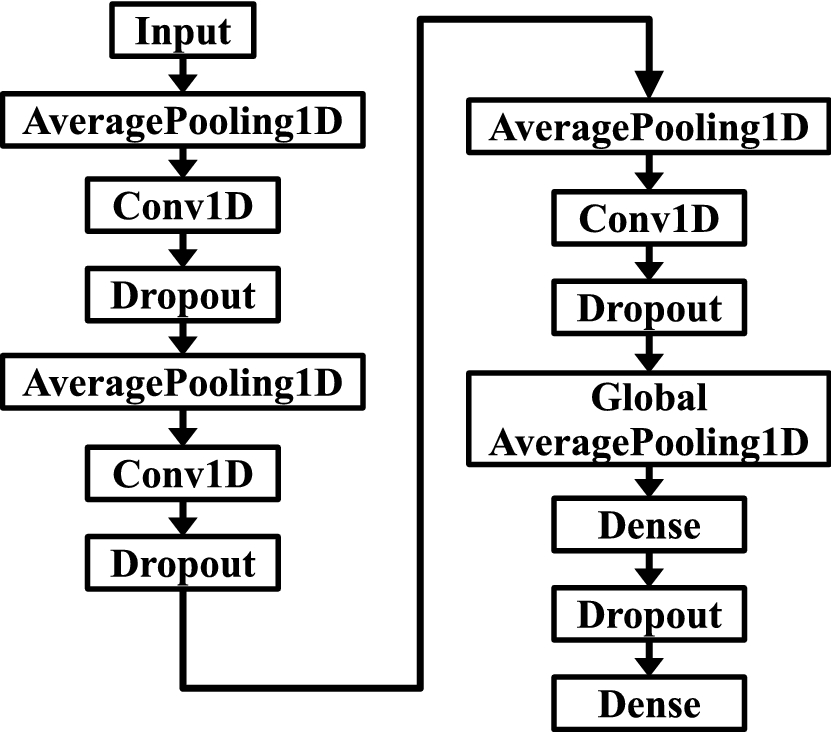

FFT TESTE


In [ ]:
# fft_cnn_train.py
import os
import h5py
import math
import torch
import random
import numpy as np
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split

# ----------------------------
# Configurações (ajustáveis)
# ----------------------------
h5file = './data_random/train_sig.h5'   # arquivo gerado pelo seu proc_images_random
checkpoint_path = './output_fft_cnn/'
os.makedirs(checkpoint_path, exist_ok=True)
checkpoint_file = os.path.join(checkpoint_path, 'best_fftcnn.pth')

batch_size = 64
num_classes = 16
epochs = 50
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
PATIENCE = 10

# ----------------------------
# Dataset 1D que lê S# do HDF5
# ----------------------------
class H5Dataset1D(Dataset):
    """
    Lê datasets S1, S2, ... (1 x L) e y1, y2,... do HDF5.
    Retorna (signal_tensor: float32 shape (1, L), label: int)
    Normaliza cada amostra para mean=0 std=1.
    """
    def __init__(self, path, s_prefix='S', y_prefix='y'):
        self.h5 = h5py.File(path, 'r')
        # identifica quantos sinais existem (procurando keys S*)
        self.keys_S = sorted([k for k in self.h5.keys() if k.startswith(s_prefix)],
                             key=lambda x: int(x[len(s_prefix):]))
        self.keys_y = sorted([k for k in self.h5.keys() if k.startswith(y_prefix)],
                             key=lambda x: int(x[len(y_prefix):]))
        assert len(self.keys_S) == len(self.keys_y), "S# and y# count mismatch"
        # get length of signals (assuming first has shape (1, L) or (L,))
        first = self.h5[self.keys_S[0]][:]
        if first.ndim == 2:
            self.sig_len = first.shape[1]
        else:
            self.sig_len = first.shape[0]
    def __len__(self):
        return len(self.keys_S)
    def __getitem__(self, idx):
        keyS = self.keys_S[idx]
        keyy = self.keys_y[idx]
        s = self.h5[keyS][:]
        # handle shapes (1, L) or (L,)
        if s.ndim == 2:
            s = s.reshape(-1)
        # normalize per-sample
        s = (s - s.mean()) / (s.std() + 1e-6)
        # shape for Conv1d: (channels, length). We have single-channel signals.
        s = np.expand_dims(s.astype(np.float32), axis=0)
        y = int(self.h5[keyy][0])
        return torch.from_numpy(s), y

# ----------------------------
# Função utilitária: prox potência de 2
# ----------------------------
def next_pow_of_two(x):
    return 1 << (x - 1).bit_length()

# ----------------------------
# Implementação FFTConv1d
# ----------------------------
class FFTConv1d(nn.Module):
    """
    Convolução 1D via FFT (same padding).
    weight shape: (out_channels, in_channels, kernel_size)
    bias shape: (out_channels,) or None
    Nota: implementado com rfft/irfft (real signals).
    """
    def __init__(self, in_channels, out_channels, kernel_size, bias=True):
        super().__init__()
        self.in_channels = in_channels
        self.out_channels = out_channels
        self.kernel_size = kernel_size
        # parâmetro de peso
        self.weight = nn.Parameter(torch.randn(out_channels, in_channels, kernel_size) * math.sqrt(2/(in_channels*kernel_size)))
        if bias:
            self.bias = nn.Parameter(torch.zeros(out_channels))
        else:
            self.bias = None

    def forward(self, x):
        # x: (batch, in_channels, L)
        batch, in_ch, L = x.shape
        k = self.kernel_size
        assert in_ch == self.in_channels, "Mismatched in_channels"

        # comprimento da convolução 'full'
        n_full = L + k - 1
        # escolher tamanho de FFT (potência de 2 para velocidade)
        fft_n = next_pow_of_two(n_full)

        # FFT do input: (batch, in_ch, fft_bins)
        Xf = torch.fft.rfft(x, n=fft_n)

        # Prepara kernel e faz FFT ao longo do eixo temporal
        # kernel padded para fft_n: shape (out_ch, in_ch, fft_n)
        device = x.device
        weight = self.weight.to(device)
        # pad kernel: colocar no shape (out_ch, in_ch, fft_n)
        pad = (0, fft_n - k)
        # weight is (out_ch, in_ch, k) -> pad to (out_ch, in_ch, fft_n)
        W = F.pad(weight, pad, "constant", 0.0)
        Wf = torch.fft.rfft(W, n=fft_n)  # (out_ch, in_ch, fft_bins)

        # agora multiplicar e somar sobre in_ch:
        # Xf: (batch, in_ch, bins)
        # Wf: (out_ch, in_ch, bins)
        # queremos Yf: (batch, out_ch, bins)
        # fazemos broadcasting: (batch, 1, in_ch, bins) * (1, out_ch, in_ch, bins) -> align
        Xf = Xf.unsqueeze(1)
        Wf = Wf.unsqueeze(0)
        Yf = torch.sum(Xf * Wf, dim=2) # sum over in_ch -> (batch, out_ch, bins)

        # inverse FFT -> (batch, out_ch, fft_n)
        y_full = torch.fft.irfft(Yf, n=fft_n)

        # crop to 'same' length (L): center crop
        # For 'same' with kernel k: crop start = floor((k-1)/2)
        start = (k - 1) // 2
        end = start + L
        y = y_full[..., start:end]

        if self.bias is not None:
            y = y + self.bias.view(1, -1, 1)

        return y  # shape (batch, out_ch, L)

# ----------------------------
# Modelo FFT-CNN 1D exemplo
# ----------------------------
class FFTCNN1D(nn.Module):
    def __init__(self, num_classes=16, in_ch=1):
        super().__init__()
        # blocos com FFTConv1d
        self.b1 = nn.Sequential(
            FFTConv1d(in_ch, 32, kernel_size=31),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2)
        )
        self.b2 = nn.Sequential(
            FFTConv1d(32, 64, kernel_size=21),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2)
        )
        self.b3 = nn.Sequential(
            FFTConv1d(64, 128, kernel_size=15),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2)
        )
        # final: global average pool + fc
        self.global_pool = nn.AdaptiveAvgPool1d(output_size=1)
        self.fc = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.4),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        # x: (batch, ch=1, L)
        x = self.b1(x)
        x = self.b2(x)
        x = self.b3(x)
        x = self.global_pool(x)   # (batch, 128, 1)
        x = self.fc(x)
        return x

# ----------------------------
# Preparar dataset + dataloaders
# ----------------------------
print("Preparando dataset HDF5...")
dataset = H5Dataset1D(h5file)
print(f"Total amostras: {len(dataset)}, sinal length: {dataset.sig_len}")

# split (90/10)
train_size = int(0.9 * len(dataset))
val_size = len(dataset) - train_size
train_ds, val_ds = random_split(dataset, [train_size, val_size])

train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=True if device.type=='cuda' else False)
val_loader = DataLoader(val_ds,   batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True if device.type=='cuda' else False)

# ----------------------------
# Instanciar modelo, loss, optimizer
# ----------------------------
model = FFTCNN1D(num_classes=num_classes, in_ch=1).to(device)
print("Modelo:")
print(model)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=3, factor=0.5)

# ----------------------------
# Função utilitária: testar se o modelo consegue overfit em um batch pequeno (debug)
# ----------------------------
def test_overfit_small_batch():
    model.train()
    small = next(iter(train_loader))
    Xs, ys = small[0].to(device), small[1].to(device)
    # tentar overfit por algumas iterações
    print("Test overfitting a small batch (debug):")
    opt = optim.Adam(model.parameters(), lr=1e-3)
    for i in range(30):
        opt.zero_grad()
        out = model(Xs)
        loss = criterion(out, ys)
        loss.backward()
        opt.step()
        if (i % 5 == 0):
            pred = out.argmax(dim=1)
            acc = (pred == ys).float().mean().item()
            print(f"  iter {i:02d}, loss={loss.item():.4f}, acc={acc*100:.1f}%")
    print("End small-batch test.")

# Uncomment para rodar o teste de overfit local (útil para debugging)
# test_overfit_small_batch()

# ----------------------------
# Loop de treino + validação
# ----------------------------
best_val_acc = 0.0
epochs_no_improve = 0

for epoch in range(1, epochs+1):
    # treino
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    for X, y in train_loader:
        X = X.to(device)   # (batch, 1, L)
        y = y.to(device)
        optimizer.zero_grad()
        out = model(X)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * X.size(0)
        preds = out.argmax(dim=1)
        correct += (preds == y).sum().item()
        total += y.size(0)

    train_loss = running_loss / total
    train_acc = 100.0 * correct / total

    # validação
    model.eval()
    val_loss = 0.0
    v_corr = 0
    v_tot = 0
    with torch.no_grad():
        for Xv, yv in val_loader:
            Xv = Xv.to(device)
            yv = yv.to(device)
            outv = model(Xv)
            lv = criterion(outv, yv)
            val_loss += lv.item() * Xv.size(0)
            pv = outv.argmax(dim=1)
            v_corr += (pv == yv).sum().item()
            v_tot += yv.size(0)
    val_loss = val_loss / v_tot
    val_acc = 100.0 * v_corr / v_tot

    # scheduler
    scheduler.step(val_loss)

    print(f"Epoch {epoch}/{epochs} | Train loss: {train_loss:.4f}, acc: {train_acc:.2f}% | Val loss: {val_loss:.4f}, acc: {val_acc:.2f}%")

    # checkpoint
    if val_acc > best_val_acc:
        print(f"  Val acc improved: {best_val_acc:.2f}% -> {val_acc:.2f}%. Saving checkpoint.")
        torch.save({'epoch': epoch, 'model_state': model.state_dict(), 'opt_state': optimizer.state_dict()}, checkpoint_file)
        best_val_acc = val_acc
        epochs_no_improve = 0
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= PATIENCE:
            print(f"No improvement for {PATIENCE} epochs. Early stopping.")
            break

print("Treinamento finalizado. Melhor val acc: %.2f%%" % best_val_acc)

Preparando dataset HDF5...
Total amostras: 76800, sinal length: 560
Modelo:
FFTCNN1D(
  (b1): Sequential(
    (0): FFTConv1d()
    (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (b2): Sequential(
    (0): FFTConv1d()
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (b3): Sequential(
    (0): FFTConv1d()
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (global_pool): AdaptiveAvgPool1d(output_size=1)
  (fc): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.4, inplace=False)
    (2): Linear(in_features=128, out_features=64, bias=True)

In [ ]:
# fft_cnn_train.py
import os
import h5py
import math
import torch
import random
import numpy as np
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split

# ----------------------------
# Configurações (ajustáveis)
# ----------------------------
h5file = './data_random/train_sig.h5'   # arquivo gerado pelo seu proc_images_random
checkpoint_path = './output_fft_cnn/'
os.makedirs(checkpoint_path, exist_ok=True)
checkpoint_file = os.path.join(checkpoint_path, 'best_fftcnn.pth')

batch_size = 64
num_classes = 16
epochs = 50
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
PATIENCE = 10

# ----------------------------
# Dataset 1D que lê S# do HDF5
# ----------------------------
class H5Dataset1D(Dataset):
    """
    Lê datasets S1, S2, ... (1 x L) e y1, y2,... do HDF5.
    Retorna (signal_tensor: float32 shape (1, L), label: int)
    Normaliza cada amostra para mean=0 std=1.
    """
    def __init__(self, path, s_prefix='S', y_prefix='y'):
        self.h5 = h5py.File(path, 'r')
        # identifica quantos sinais existem (procurando keys S*)
        self.keys_S = sorted([k for k in self.h5.keys() if k.startswith(s_prefix)],
                             key=lambda x: int(x[len(s_prefix):]))
        self.keys_y = sorted([k for k in self.h5.keys() if k.startswith(y_prefix)],
                             key=lambda x: int(x[len(y_prefix):]))
        assert len(self.keys_S) == len(self.keys_y), "S# and y# count mismatch"
        # get length of signals (assuming first has shape (1, L) or (L,))
        first = self.h5[self.keys_S[0]][:]
        if first.ndim == 2:
            self.sig_len = first.shape[1]
        else:
            self.sig_len = first.shape[0]
    def __len__(self):
        return len(self.keys_S)
    def __getitem__(self, idx):
        keyS = self.keys_S[idx]
        keyy = self.keys_y[idx]
        s = self.h5[keyS][:]
        # handle shapes (1, L) or (L,)
        if s.ndim == 2:
            s = s.reshape(-1)
        # normalize per-sample
        s = (s - s.mean()) / (s.std() + 1e-6)
        # shape for Conv1d: (channels, length). We have single-channel signals.
        s = np.expand_dims(s.astype(np.float32), axis=0)
        y = int(self.h5[keyy][0])
        return torch.from_numpy(s), y

# ----------------------------
# Função utilitária: prox potência de 2
# ----------------------------
def next_pow_of_two(x):
    return 1 << (x - 1).bit_length()

# ----------------------------
# Implementação FFTConv1d
# ----------------------------
class FFTConv1d(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size, input_length=None, bias=True):
        super().__init__()
        self.in_channels = in_channels
        self.out_channels = out_channels
        self.kernel_size = kernel_size
        self.weight = nn.Parameter(torch.randn(out_channels, in_channels, kernel_size) *
                                   math.sqrt(2/(in_channels*kernel_size)))
        self.bias = nn.Parameter(torch.zeros(out_channels)) if bias else None
        # se você souber o comprimento L do input (ex: dataset.sig_len), passe aqui
        if input_length is not None:
            n_full = input_length + kernel_size - 1
            self.fft_n = next_pow_of_two(n_full)
        else:
            self.fft_n = None

    def forward(self, x):
        # x shape (batch, in_ch, L)
        batch, in_ch, L = x.shape
        if self.fft_n is None:
            n_full = L + self.kernel_size - 1
            fft_n = next_pow_of_two(n_full)
        else:
            fft_n = self.fft_n

        # FFT do input
        Xf = torch.fft.rfft(x, n=fft_n)  # (batch, in_ch, bins)
        # FFT do peso (torch.fft.rfft aceita n -> faz pad implicitamente)
        Wf = torch.fft.rfft(self.weight, n=fft_n)  # (out_ch, in_ch, bins)
        # multiplicação e soma sobre in_ch
        Yf = (Xf.unsqueeze(1) * Wf.unsqueeze(0)).sum(dim=2)  # (batch, out_ch, bins)
        y_full = torch.fft.irfft(Yf, n=fft_n)
        start = (self.kernel_size - 1) // 2
        end = start + L
        y = y_full[..., start:end]
        if self.bias is not None:
            y = y + self.bias.view(1, -1, 1)
        return y


# ----------------------------
# Modelo FFT-CNN 1D exemplo
# ----------------------------
class FFTCNN1D(nn.Module):
    def __init__(self, num_classes=16, in_ch=1):
        super().__init__()
        # blocos com FFTConv1d
        self.b1 = nn.Sequential(
            FFTConv1d(in_ch, 32, kernel_size=31),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2)
        )
        self.b2 = nn.Sequential(
            FFTConv1d(32, 64, kernel_size=21),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2)
        )
        self.b3 = nn.Sequential(
            FFTConv1d(64, 128, kernel_size=15),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2)
        )
        # final: global average pool + fc
        self.global_pool = nn.AdaptiveAvgPool1d(output_size=1)
        self.fc = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.4),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        # x: (batch, ch=1, L)
        x = self.b1(x)
        x = self.b2(x)
        x = self.b3(x)
        x = self.global_pool(x)   # (batch, 128, 1)
        x = self.fc(x)
        return x

# ----------------------------
# Preparar dataset + dataloaders
# ----------------------------
print("Preparando dataset HDF5...")
dataset = H5Dataset1D(h5file)
print(f"Total amostras: {len(dataset)}, sinal length: {dataset.sig_len}")

# split (90/10)
train_size = int(0.9 * len(dataset))
val_size = len(dataset) - train_size
train_ds, val_ds = random_split(dataset, [train_size, val_size])

train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=True if device.type=='cuda' else False)
val_loader = DataLoader(val_ds,   batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True if device.type=='cuda' else False)

# ----------------------------
# Instanciar modelo, loss, optimizer
# ----------------------------
model = FFTCNN1D(num_classes=num_classes, in_ch=1).to(device)
print("Modelo:")
print(model)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=3, factor=0.5)

# ----------------------------
# Função utilitária: testar se o modelo consegue overfit em um batch pequeno (debug)
# ----------------------------
def test_overfit_small_batch():
    model.train()
    small = next(iter(train_loader))
    Xs, ys = small[0].to(device), small[1].to(device)
    # tentar overfit por algumas iterações
    print("Test overfitting a small batch (debug):")
    opt = optim.Adam(model.parameters(), lr=1e-3)
    for i in range(30):
        opt.zero_grad()
        out = model(Xs)
        loss = criterion(out, ys)
        loss.backward()
        opt.step()
        if (i % 5 == 0):
            pred = out.argmax(dim=1)
            acc = (pred == ys).float().mean().item()
            print(f"  iter {i:02d}, loss={loss.item():.4f}, acc={acc*100:.1f}%")
    print("End small-batch test.")

# Uncomment para rodar o teste de overfit local (útil para debugging)
# test_overfit_small_batch()

# ----------------------------
# Loop de treino + validação
# ----------------------------
best_val_acc = 0.0
epochs_no_improve = 0

for epoch in range(1, epochs+1):
    # treino
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    for X, y in train_loader:
        X = X.to(device)   # (batch, 1, L)
        y = y.to(device)
        optimizer.zero_grad()
        out = model(X)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * X.size(0)
        preds = out.argmax(dim=1)
        correct += (preds == y).sum().item()
        total += y.size(0)

    train_loss = running_loss / total
    train_acc = 100.0 * correct / total

    # validação
    model.eval()
    val_loss = 0.0
    v_corr = 0
    v_tot = 0
    with torch.no_grad():
        for Xv, yv in val_loader:
            Xv = Xv.to(device)
            yv = yv.to(device)
            outv = model(Xv)
            lv = criterion(outv, yv)
            val_loss += lv.item() * Xv.size(0)
            pv = outv.argmax(dim=1)
            v_corr += (pv == yv).sum().item()
            v_tot += yv.size(0)
    val_loss = val_loss / v_tot
    val_acc = 100.0 * v_corr / v_tot

    # scheduler
    scheduler.step(val_loss)

    print(f"Epoch {epoch}/{epochs} | Train loss: {train_loss:.4f}, acc: {train_acc:.2f}% | Val loss: {val_loss:.4f}, acc: {val_acc:.2f}%")

    # checkpoint
    if val_acc > best_val_acc:
        print(f"  Val acc improved: {best_val_acc:.2f}% -> {val_acc:.2f}%. Saving checkpoint.")
        torch.save({'epoch': epoch, 'model_state': model.state_dict(), 'opt_state': optimizer.state_dict()}, checkpoint_file)
        best_val_acc = val_acc
        epochs_no_improve = 0
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= PATIENCE:
            print(f"No improvement for {PATIENCE} epochs. Early stopping.")
            break

print("Treinamento finalizado. Melhor val acc: %.2f%%" % best_val_acc)

Preparando dataset HDF5...
Total amostras: 76800, sinal length: 560
Modelo:
FFTCNN1D(
  (b1): Sequential(
    (0): FFTConv1d()
    (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (b2): Sequential(
    (0): FFTConv1d()
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (b3): Sequential(
    (0): FFTConv1d()
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (global_pool): AdaptiveAvgPool1d(output_size=1)
  (fc): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.4, inplace=False)
    (2): Linear(in_features=128, out_features=64, bias=True)